# Asignación de Subsidios de Vivienda en Colombia: pronóstico del valor asignado y perfiles de asignación

**Proyecto Final (20%) · Analítica de Negocios · Universidad EAFIT**

**Autor:** John Alexánder Restrepo Mesa

**Fecha:** noviembre de 2026

**Modelos aplicados:** (1) Regresión lineal múltiple (pronóstico) y (2) K-Means (agrupamiento).

**Contenido**
1. Introducción
2. Definición del problema
3. Objetivos
4. Recopilar y preparar datos
5. Definir el modelo, el método de trabajo y las métricas
6. Desplegar el modelo y validar (resultados)
7. Discusión de los resultados
8. Posibles limitaciones y retos
9. Consideraciones éticas y prácticas
10. Conclusiones
11. Recomendaciones
12. Bibliografía

## 1. Introducción

El acceso a una vivienda digna es una de las políticas públicas con mayor impacto social y fiscal en Colombia. El Estado entrega el **Subsidio Familiar de Vivienda (SFV)** a través de múltiples programas (Mi Casa Ya, Vivienda Gratuita, Bolsa Desplazados, Semillero de Propietarios, entre otros), en distintos territorios y a lo largo de más de veinte años. Esa diversidad produce una base de datos grande, pero difícil de leer a simple vista: no es evidente cuánto cuesta en promedio apoyar a un hogar, cómo cambió ese costo en el tiempo, ni qué tipos de asignación existen realmente detrás de las cifras.

En este portafolio analizamos la base **Subsidios de Vivienda Asignados** (87,173 registros, años 2003 a 2026), publicada como dato abierto del Gobierno de Colombia (portal datos.gov.co, localizable mediante Google Dataset Search). Cada registro resume las asignaciones de un programa, en un municipio y un año, con su número de hogares y su valor total en pesos.

Aplicamos dos técnicas vistas en clase: una **regresión lineal** para pronosticar el valor asignado y **K-Means** para descubrir perfiles de asignación. El objetivo final es traducir los resultados en hallazgos útiles para quien planea y presupuesta la política de vivienda.

## 2. Definición del problema

Una entidad que asigna subsidios necesita anticipar cuántos recursos comprometerá y entender a qué tipo de asignaciones corresponde cada peso. Las preguntas de negocio que guían el trabajo son:

**Descriptivas**
- ¿Qué relación existe entre el número de hogares beneficiados y el valor asignado?
- ¿Cómo varía el valor según programa, departamento, municipio y año?

**Predictivas**
- ¿Es posible estimar el valor asignado a partir de características disponibles antes de la asignación (hogares, programa, departamento, año)?
- ¿Existen grupos de registros con comportamientos y perfiles similares?

**Estratégicas**
- ¿Qué información de los modelos puede apoyar la toma de decisiones sobre la distribución de recursos?

## 3. Objetivos

**Objetivo general.** Analizar los subsidios de vivienda asignados mediante analítica predictiva y descriptiva, para estimar el valor asignado y encontrar agrupaciones que aporten a la toma de decisiones.

**Objetivos específicos**
1. Describir la estructura de la base de datos y sus variables, identificando las de pronóstico, clasificación y agrupamiento.
2. Limpiar y transformar los datos para el modelado.
3. Construir y evaluar un modelo de regresión lineal para pronosticar el valor asignado, con validación temporal.
4. Aplicar K-Means para identificar perfiles de asignación y seleccionar el número de grupos con criterio matemático.
5. Interpretar los resultados en lenguaje de negocio y formular recomendaciones.

## 4. Recopilar y preparar datos

### 4.1 Carga de datos

La base debe estar en el mismo repositorio (archivo `Subsidios_De_Vivienda_Asignados_20261114.xlsx`). La celda siguiente la busca en la carpeta de trabajo y, si no la encuentra (por ejemplo, en una sesión nueva de Colab), pide subirla.

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.2f}".format
SEED = 42

ARCHIVO = "Subsidios_De_Vivienda_Asignados_20261114.xlsx"

def cargar():
    if os.path.exists(ARCHIVO):          # archivo en la misma carpeta (repositorio clonado o sesión de Colab)
        return pd.read_excel(ARCHIVO)
    from google.colab import files       # en Colab: pide subir el archivo
    subido = files.upload()
    return pd.read_excel(list(subido.keys())[0])

raw = cargar()
print("Filas y columnas:", raw.shape)
raw.head()

Filas y columnas: (87173, 9)


,Departamento,Código Divipola Departamento,Municipio,Código Divipola Municipio,Programa,Año de Asignación,Estado de Postulación,Hogares,Valor Asignado
0,NORTE DE SANTANDER,54,SARDINATA,54720,Bolsa Desplazados,2007,Asignados,36,"386,259,750.00"
1,CAUCA,19,POPAYÁN,19001,MI CASA YA,2020,Asignados,4,"87,780,300.00"
2,VALLE DEL CAUCA,76,CANDELARIA,76130,MI CASA YA,2021,Asignados,24,"572,371,380.00"
3,CAUCA,19,SANTANDER DE QUILICHAO,19698,MI CASA YA,2022,Asignados,10,"260,000,000.00"
4,"BOGOTÁ, D.C.",11,"BOGOTÁ, D.C.",11001,Semillero de Propietarios Arriendo,2022,Asignados,2,"30,689,280.00"


### 4.2 Descripción de la base de datos y de las variables

In [ ]:
diccionario = pd.DataFrame({
    "Variable": ["Departamento", "Código Divipola Departamento", "Municipio", "Código Divipola Municipio",
                 "Programa", "Año de Asignación", "Estado de Postulación", "Hogares", "Valor Asignado"],
    "Tipo": ["Categórica", "Identificador", "Categórica", "Identificador", "Categórica", "Numérica discreta",
             "Categórica", "Numérica discreta", "Numérica continua (COP)"],
    "Descripción": [
        "Departamento donde se asigna el subsidio.",
        "Código DANE (Divipola) del departamento.",
        "Municipio de la asignación.",
        "Código DANE (Divipola) del municipio.",
        "Programa del que proviene el subsidio (Mi Casa Ya, Vivienda Gratuita, Bolsa Desplazados, etc.).",
        "Año en que se asignó el subsidio (2003 a 2026).",
        "Situación del subsidio: asignado, vencido, renunciado, revocado, restituido, etc.",
        "Número de hogares incluidos en el registro.",
        "Valor total asignado al registro, en pesos colombianos nominales."],
    "Uso potencial": ["Clasificación / agrupamiento", "Llave de unión (no se modela)", "Clasificación / agrupamiento",
                      "Llave de unión (no se modela)", "Clasificación / agrupamiento", "Pronóstico (tendencia) y agrupamiento",
                      "Filtro de calidad / clasificación", "Pronóstico (explicativa) y agrupamiento",
                      "Pronóstico (variable objetivo) y agrupamiento"]})
diccionario

,Variable,Tipo,Descripción,Uso potencial
0,Departamento,Categórica,Departamento donde se asigna el subsidio.,Clasificación / agrupamiento
1,Código Divipola Departamento,Identificador,Código DANE (Divipola) del departamento.,Llave de unión (no se modela)
2,Municipio,Categórica,Municipio de la asignación.,Clasificación / agrupamiento
3,Código Divipola Municipio,Identificador,Código DANE (Divipola) del municipio.,Llave de unión (no se modela)
4,Programa,Categórica,Programa del que proviene el subsidio (Mi Casa...,Clasificación / agrupamiento
5,Año de Asignación,Numérica discreta,Año en que se asignó el subsidio (2003 a 2026).,Pronóstico (tendencia) y agrupamiento
6,Estado de Postulación,Categórica,"Situación del subsidio: asignado, vencido, ren...",Filtro de calidad / clasificación
7,Hogares,Numérica discreta,Número de hogares incluidos en el registro.,Pronóstico (explicativa) y agrupamiento
8,Valor Asignado,Numérica continua (COP),"Valor total asignado al registro, en pesos col...",Pronóstico (variable objetivo) y agrupamiento


In [ ]:
print("Valores nulos por columna:")
print(raw.isna().sum().to_string())
print()
print("Registros duplicados exactos:", raw.duplicated().sum())
print("Registros con Hogares = 0 o Valor = 0:", ((raw['Hogares'] <= 0) | (raw['Valor Asignado'] <= 0)).sum())
print()
print("Rango de años:", raw['Año de Asignación'].min(), "a", raw['Año de Asignación'].max())
print("Departamentos:", raw['Departamento'].nunique(), "| Municipios:", raw['Municipio'].nunique(),
      "| Programas:", raw['Programa'].nunique(), "| Estados:", raw['Estado de Postulación'].nunique())
raw[['Hogares', 'Valor Asignado']].describe(percentiles=[.5, .9, .99])

Valores nulos por columna:
Departamento                    0
Código Divipola Departamento    0
Municipio                       0
Código Divipola Municipio       0
Programa                        0
Año de Asignación               0
Estado de Postulación           0
Hogares                         0
Valor Asignado                  0

Registros duplicados exactos: 30393
Registros con Hogares = 0 o Valor = 0: 47

Rango de años: 2003 a 2026
Departamentos: 33 | Municipios: 991 | Programas: 26 | Estados: 31


,Hogares,Valor Asignado
count,"87,173.00","87,173.00"
mean,11.56,"234,384,392.21"
std,51.77,"1,106,960,137.15"
min,0.00,0.00
50%,2.00,"40,000,000.00"
90%,23.00,"417,600,000.00"
99%,147.00,"3,357,154,763.60"
max,"6,100.00","65,843,588,500.00"


### 4.3 Limpieza y preparación

Decisiones tomadas y su justificación:

1. **Nombres de columnas cortos** para facilitar el código.
2. **Se eliminan los registros con 0 hogares o valor 0** (no representan una asignación real y hacen imposible calcular el valor por hogar).
3. **Se conservan solo los registros en estado "Asignados"** para modelar. Los demás estados (vencidos, renuncias, revocados, restituciones) describen el destino posterior del subsidio, no una asignación efectiva, y mezclarlos distorsionaría el pronóstico. Los estados "Asignados" concentran 68,936 de 87,173 registros y más del 90% del valor.
4. **Los duplicados exactos no se eliminan.** La base no trae un identificador del registro y, al ser datos agregados por programa, municipio, año, estado, hogares y valor, es esperable que existan combinaciones idénticas (por ejemplo, asignaciones individuales de 1 hogar con el valor fijo del subsidio). Eliminarlos borraría asignaciones reales.
5. **Variables derivadas:** valor por hogar (`vh = valor / hogares`) y versiones logarítmicas, porque `hogares` y `valor` tienen colas muy largas.
6. **Programas:** se agrupan los 8 más frecuentes y el resto en "Otros" para evitar decenas de variables con muy pocos datos.

In [ ]:
df = raw.rename(columns={"Departamento": "dep", "Código Divipola Departamento": "cod_dep", "Municipio": "mun",
                         "Código Divipola Municipio": "cod_mun", "Programa": "prog", "Año de Asignación": "anio",
                         "Estado de Postulación": "estado", "Hogares": "hog", "Valor Asignado": "val"})

n0 = len(df)
df = df[(df.hog > 0) & (df.val > 0)]
n1 = len(df)
cuota_asignados = df[df.estado == "Asignados"].val.sum() / df.val.sum()
d = df[df.estado == "Asignados"].copy()
d["vh"] = d.val / d.hog
top_prog = d.prog.value_counts().head(8).index
d["prog_g"] = d.prog.where(d.prog.isin(top_prog), "Otros")

print(f"Registros originales: {n0:,} | sin ceros: {n1:,} | en estado 'Asignados': {len(d):,}")
print(f"Participación de 'Asignados' en el valor total: {cuota_asignados:.1%}")
print(f"Hogares: {d.hog.sum():,} | Valor total: {d.val.sum()/1e12:,.2f} billones de COP")
d.head()

Registros originales: 87,173 | sin ceros: 87,126 | en estado 'Asignados': 68,890
Participación de 'Asignados' en el valor total: 94.8%
Hogares: 912,609 | Valor total: 19.37 billones de COP


,dep,cod_dep,mun,cod_mun,prog,anio,estado,hog,val,vh,prog_g
0,NORTE DE SANTANDER,54,SARDINATA,54720,Bolsa Desplazados,2007,Asignados,36,"386,259,750.00","10,729,437.50",Bolsa Desplazados
1,CAUCA,19,POPAYÁN,19001,MI CASA YA,2020,Asignados,4,"87,780,300.00","21,945,075.00",MI CASA YA
2,VALLE DEL CAUCA,76,CANDELARIA,76130,MI CASA YA,2021,Asignados,24,"572,371,380.00","23,848,807.50",MI CASA YA
3,CAUCA,19,SANTANDER DE QUILICHAO,19698,MI CASA YA,2022,Asignados,10,"260,000,000.00","26,000,000.00",MI CASA YA
4,"BOGOTÁ, D.C.",11,"BOGOTÁ, D.C.",11001,Semillero de Propietarios Arriendo,2022,Asignados,2,"30,689,280.00","15,344,640.00",Semillero de Propietarios Arriendo


### 4.4 Análisis exploratorio (EDA)

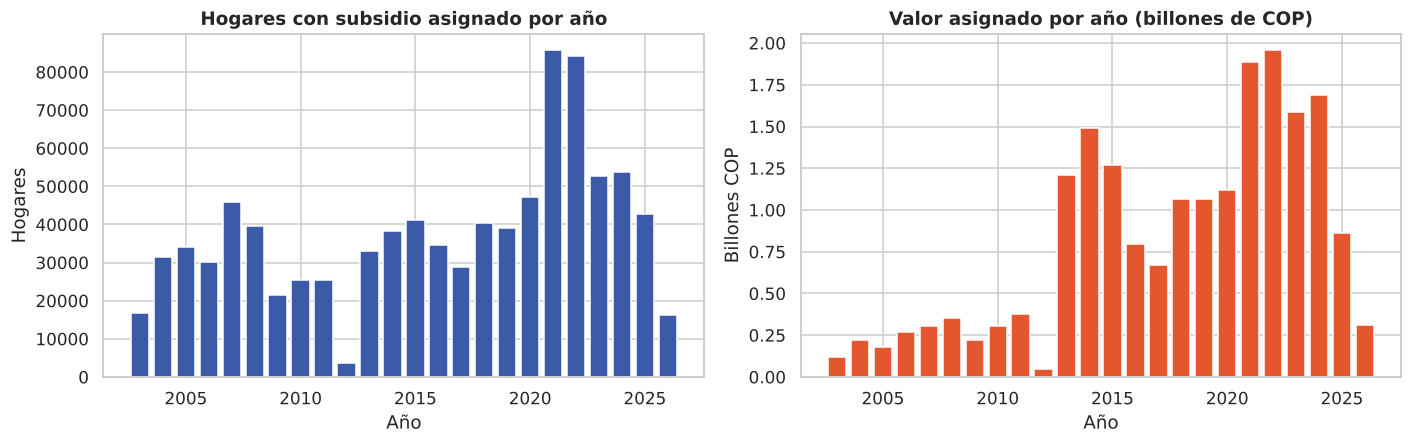

anio,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
hogares,"16,847.00","31,537.00","34,141.00","30,241.00","45,998.00","39,643.00","21,472.00","25,338.00","25,421.00","3,628.00",...,"28,792.00","40,492.00","39,135.00","47,306.00","85,693.00","84,162.00","52,818.00","53,811.00","42,625.00","16,266.00"
valor,"117,885,323,280.00","220,038,501,290.18","178,718,006,820.92","269,882,525,586.20","302,304,418,102.28","352,483,331,553.89","218,466,169,087.16","307,278,169,766.00","378,972,582,128.00","50,086,781,435.00",...,"669,079,867,420.90","1,065,798,608,556.38","1,067,965,491,078.70","1,118,871,838,145.22","1,888,325,330,477.40","1,956,174,976,705.59","1,585,094,641,346.97","1,689,432,825,426.77","860,274,482,208.16","309,985,177,281.12"
vh_millones,7.00,6.98,5.23,8.92,6.57,8.89,10.17,12.13,14.91,13.81,...,23.24,26.32,27.29,23.65,22.04,23.24,30.01,31.40,20.18,19.06


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
anual = d.groupby("anio").agg(hogares=("hog", "sum"), valor=("val", "sum"))
ax[0].bar(anual.index, anual.hogares, color="#3B5BA9")
ax[0].set_title("Hogares con subsidio asignado por año"); ax[0].set_xlabel("Año"); ax[0].set_ylabel("Hogares")
ax[1].bar(anual.index, anual.valor / 1e12, color="#E4572E")
ax[1].set_title("Valor asignado por año (billones de COP)"); ax[1].set_xlabel("Año"); ax[1].set_ylabel("Billones COP")
plt.tight_layout(); plt.show()
anual.assign(vh_millones=lambda x: x.valor / x.hogares / 1e6).round(2).T

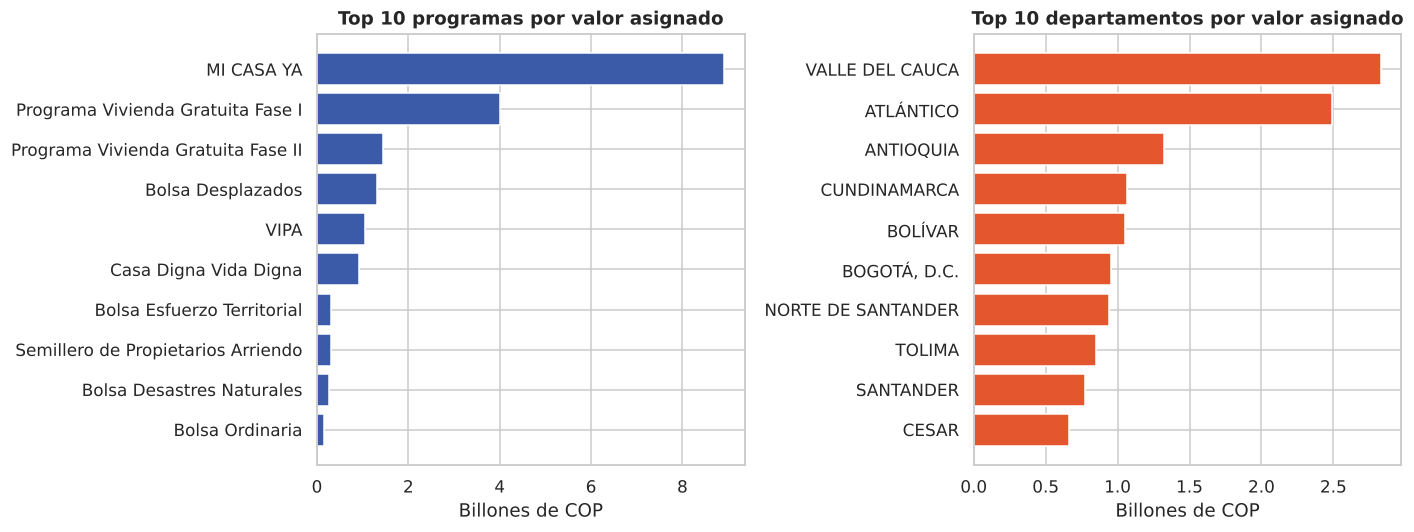

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
p = d.groupby("prog").agg(val=("val", "sum"), hog=("hog", "sum")).sort_values("val").tail(10)
ax[0].barh(p.index, p.val / 1e12, color="#3B5BA9"); ax[0].set_title("Top 10 programas por valor asignado")
ax[0].set_xlabel("Billones de COP")
dp = d.groupby("dep").val.sum().sort_values().tail(10)
ax[1].barh(dp.index, dp / 1e12, color="#E4572E"); ax[1].set_title("Top 10 departamentos por valor asignado")
ax[1].set_xlabel("Billones de COP")
plt.tight_layout(); plt.show()

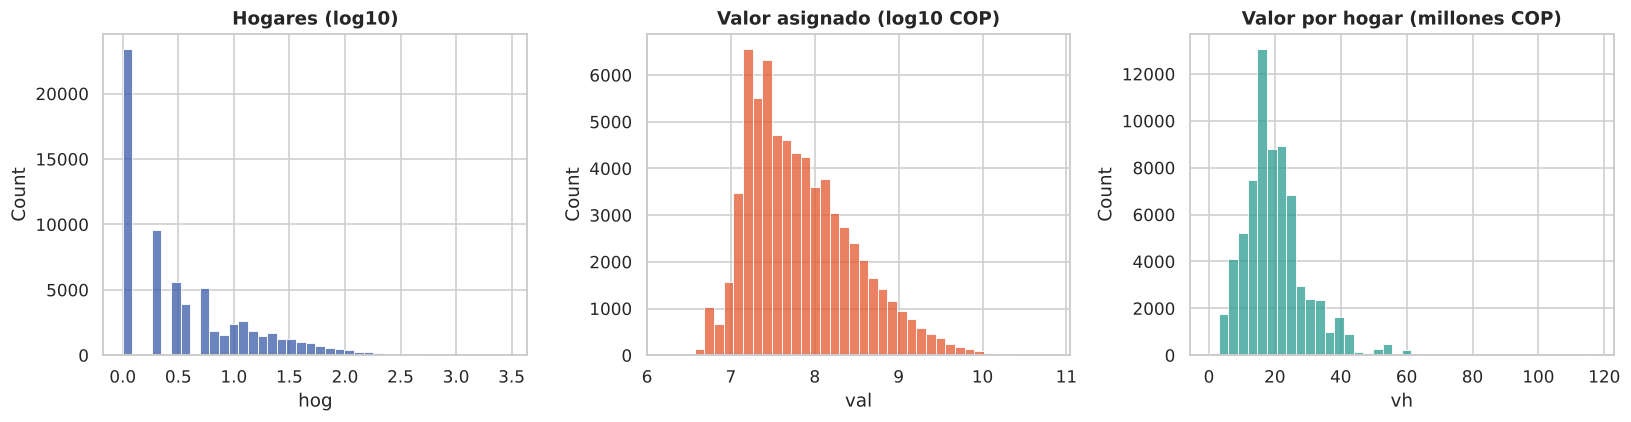

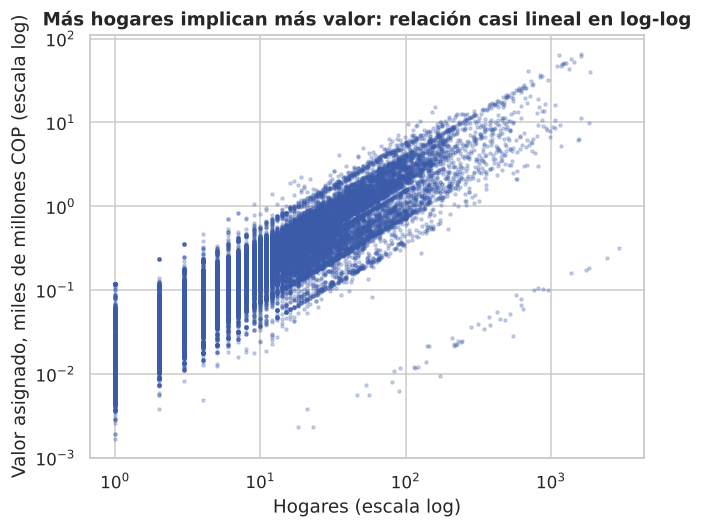

Correlación de Pearson hogares vs valor (escala original): 0.755
Correlación hogares vs valor (escala log): 0.936


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(d.hog), bins=40, ax=ax[0], color="#3B5BA9"); ax[0].set_title("Hogares (log10)")
sns.histplot(np.log10(d.val), bins=40, ax=ax[1], color="#E4572E"); ax[1].set_title("Valor asignado (log10 COP)")
sns.histplot(d.vh / 1e6, bins=40, ax=ax[2], color="#2A9D8F"); ax[2].set_title("Valor por hogar (millones COP)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(d.hog, d.val / 1e9, s=4, alpha=.25, color="#3B5BA9")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Hogares (escala log)"); ax.set_ylabel("Valor asignado, miles de millones COP (escala log)")
ax.set_title("Más hogares implican más valor: relación casi lineal en log-log")
plt.show()
print("Correlación de Pearson hogares vs valor (escala original):", round(d.hog.corr(d.val), 3))
print("Correlación hogares vs valor (escala log):", round(np.log(d.hog).corr(np.log(d.val)), 3))

**Lectura del EDA.** Tanto `hogares` como `valor` tienen colas muy largas: la mediana es de 3 hogares y 52 millones de pesos por registro, pero el máximo llega a 2,935 hogares y más de 65 mil millones. Pocos registros enormes (sobre todo de Vivienda Gratuita) pesan mucho en los totales. Por eso trabajamos también en escala logarítmica, donde la relación hogares-valor es casi lineal.

## 5. Definir el modelo, el método de trabajo y las métricas

### 5.1 Modelo 1: regresión lineal múltiple (pronóstico)

- **Variable objetivo:** `val` (valor asignado).
- **Variables explicativas:** `hog` (numérica), `anio` (numérica), `prog_g` y `dep` (categóricas, con codificación one-hot).
- **Validación temporal:** el modelo se entrena con asignaciones de **2003 a 2022** y se evalúa en **2023 a 2026**. Es la forma realista de probar un pronóstico: predecir el futuro con información del pasado, sin mezclar años al azar.
- **Dos versiones:** (a) regresión sobre el valor en pesos y (b) regresión **log-log** (`ln valor` contra `ln hogares`), pensada para datos con colas largas.
- **Referencia (baseline):** `hogares × valor medio por hogar del periodo de entrenamiento`. Un modelo solo vale la pena si supera esta regla simple.

**Métricas** (las mismas de la presentación): MAE (error promedio en pesos), RMSE (penaliza errores grandes) y R² (proporción de variabilidad explicada). Se agrega la mediana del error absoluto (MdAE), que es robusta a los registros gigantes, y el R² en escala log.

### 5.2 Modelo 2: K-Means (agrupamiento)

- **Variables:** `ln hogares`, `ln valor`, `ln valor por hogar` y `año`, estandarizadas (media 0, desviación 1) para que ninguna escala domine la distancia.
- **Número de grupos (k):** se evalúa de 2 a 8 con el método del codo (inercia) y el **coeficiente de silueta**.
- **Interpretación:** se perfila cada grupo con medianas, participación en hogares y valor, y composición por programa.

### 5.3 Paso a paso

1. Cargar y entender los datos. 2. Limpiar. 3. Explorar. 4. Construir variables. 5. Separar entrenamiento y prueba por año. 6. Entrenar la regresión. 7. Evaluar contra el baseline. 8. Estandarizar y probar valores de k. 9. Entrenar K-Means con el k elegido. 10. Interpretar para negocio.

## 6. Desplegar el modelo y validar (resultados)

### 6.1 Regresión lineal

In [ ]:
X = pd.get_dummies(d[["hog", "anio", "prog_g", "dep"]], columns=["prog_g", "dep"], drop_first=True).astype(float)
y = d.val
entrena = d.anio <= 2022
prueba = ~entrena
print(f"Entrenamiento (2003-2022): {entrena.sum():,} registros | Prueba (2023-2026): {prueba.sum():,} registros")

def metricas(nombre, real, pred):
    return {"Modelo": nombre,
            "MAE (millones COP)": mean_absolute_error(real, pred) / 1e6,
            "MdAE (millones COP)": np.median(np.abs(real - pred)) / 1e6,
            "RMSE (millones COP)": mean_squared_error(real, pred) ** .5 / 1e6,
            "R2": r2_score(real, pred),
            "R2 en log": r2_score(np.log(real), np.log(np.clip(pred, 1, None)))}

# Baseline
vh_train = d.val[entrena].sum() / d.hog[entrena].sum()
pred_base = d.hog[prueba] * vh_train

# (a) regresión lineal en pesos
m_raw = LinearRegression().fit(X[entrena], y[entrena])
pred_raw = np.clip(m_raw.predict(X[prueba]), 0, None)

# (b) regresión log-log
Xl = X.assign(hog=np.log(X.hog))
m_log = LinearRegression().fit(Xl[entrena], np.log(y[entrena]))
resid_train = np.log(y[entrena]) - m_log.predict(Xl[entrena])
smear = np.mean(np.exp(resid_train))          # corrección de sesgo por retransformación (Duan)
pred_log = np.exp(m_log.predict(Xl[prueba])) * smear

tabla = pd.DataFrame([metricas("Baseline: hogares x valor medio por hogar", y[prueba], pred_base),
                      metricas("Regresión lineal (pesos)", y[prueba], pred_raw),
                      metricas("Regresión lineal log-log", y[prueba], pred_log)]).set_index("Modelo")
tabla.round(3)

Entrenamiento (2003-2022): 55,658 registros | Prueba (2023-2026): 13,232 registros


,MAE (millones COP),MdAE (millones COP),RMSE (millones COP),R2,R2 en log
Modelo,,,,,
Baseline: hogares x valor medio por hogar,130.64,34.16,373.23,0.76,0.87
Regresión lineal (pesos),216.81,165.61,401.36,0.73,-0.92
Regresión lineal log-log,40.46,10.19,161.33,0.96,0.97


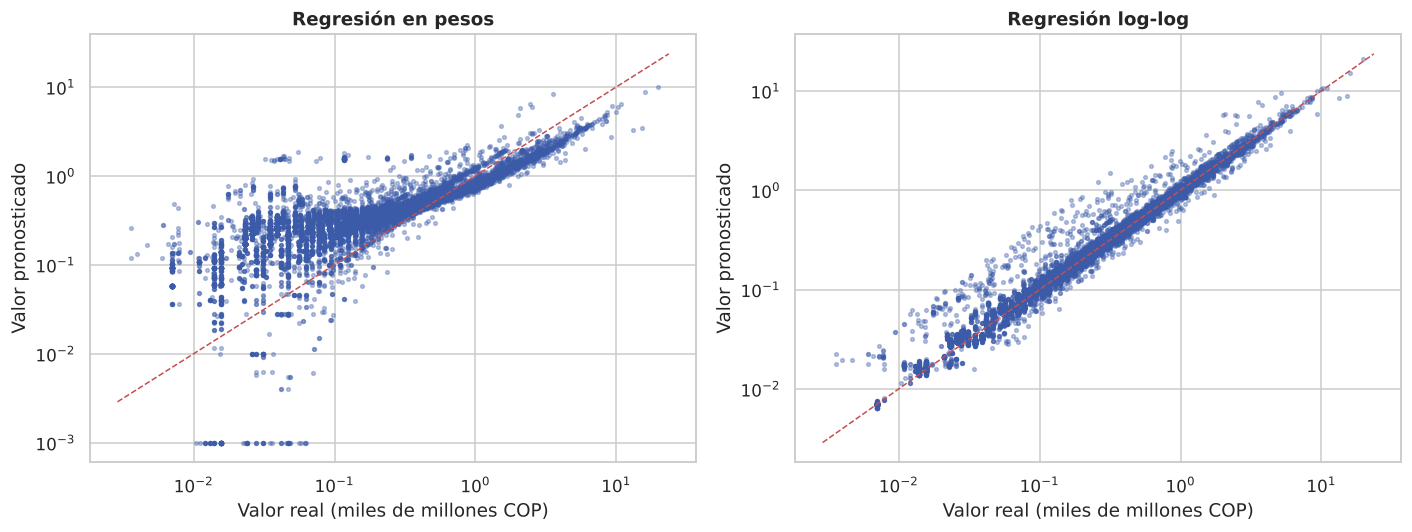

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
real = y[prueba].values
for a, pred, t in [(ax[0], pred_raw, "Regresión en pesos"), (ax[1], pred_log, "Regresión log-log")]:
    a.scatter(real / 1e9, np.clip(pred, 1e6, None) / 1e9, s=6, alpha=.35, color="#3B5BA9")
    lim = [real.min() / 1e9 * .8, real.max() / 1e9 * 1.2]
    a.plot(lim, lim, "r--", lw=1); a.set_xscale("log"); a.set_yscale("log")
    a.set_xlabel("Valor real (miles de millones COP)"); a.set_ylabel("Valor pronosticado"); a.set_title(t)
plt.tight_layout(); plt.show()

In [ ]:
coef = pd.Series(m_log.coef_, index=Xl.columns)
print("Intercepto (log):", round(m_log.intercept_, 3))
print("Elasticidad de hogares (coef. de ln hogares):", round(coef["hog"], 3))
print("Efecto anual (aprox. % de cambio por año, a igual hogares y programa):", f"{np.expm1(coef['anio']):.2%}")
print()
efectos = (np.expm1(coef.filter(like="prog_g_")) * 100).round(1).sort_values()
efectos.index = efectos.index.str.replace("prog_g_", "")
print("Diferencia porcentual del valor frente al programa de referencia, a igual hogares, año y departamento:")
print("(referencia: Bolsa Desplazados)")
print(efectos.to_string())

Intercepto (log): -201.643
Elasticidad de hogares (coef. de ln hogares): 1.002
Efecto anual (aprox. % de cambio por año, a igual hogares y programa): 11.44%

Diferencia porcentual del valor frente al programa de referencia, a igual hogares, año y departamento:
(referencia: Bolsa Desplazados)
Semillero de Propietarios Ahorro     -87.80
Casa Digna Vida Digna                -78.30
Semillero de Propietarios Arriendo   -70.50
MI CASA YA                           -49.20
VIPA                                 -26.30
Otros                                -21.70
Bolsa Esfuerzo Territorial           -14.20
Programa Vivienda Gratuita Fase I     56.40


Registros de prueba pronosticados con error relativo menor a 25%: 88.1%
Registros con error relativo menor a 50%: 96.0%


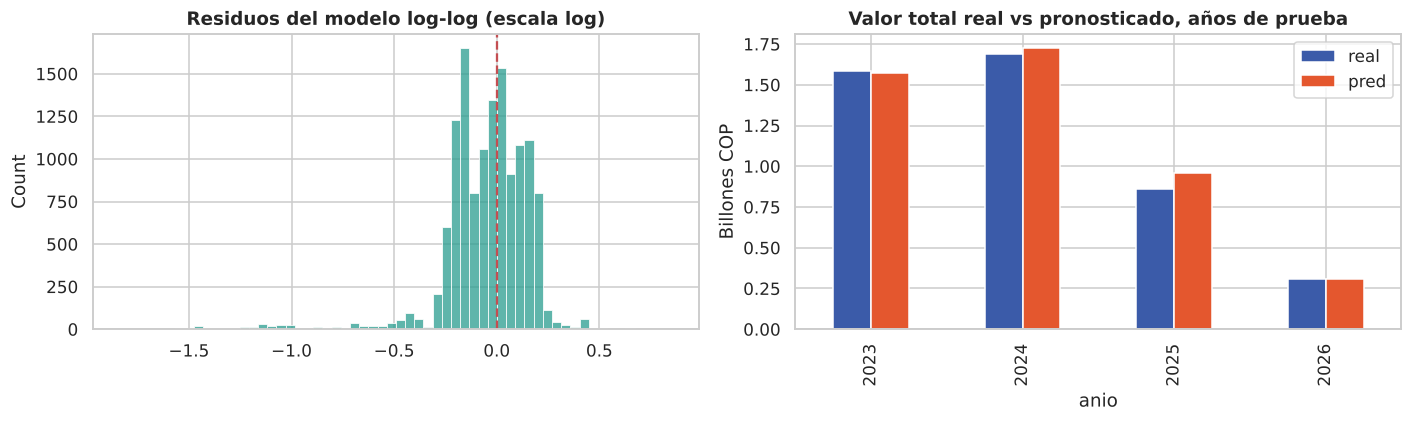

,real,pred,error_pct
anio,,,
2023,1.59,1.57,-0.65
2024,1.69,1.73,2.11
2025,0.86,0.96,11.46
2026,0.31,0.31,-0.88


In [ ]:
res = np.log(real) - np.log(np.clip(pred_log, 1, None))
err_rel = np.abs(pred_log - real) / real
print(f"Registros de prueba pronosticados con error relativo menor a 25%: {(err_rel < .25).mean():.1%}")
print(f"Registros con error relativo menor a 50%: {(err_rel < .50).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(res, bins=60, ax=ax[0], color="#2A9D8F"); ax[0].axvline(0, color="r", ls="--")
ax[0].set_title("Residuos del modelo log-log (escala log)")
por_anio = pd.DataFrame({"anio": d.anio[prueba].values, "real": real, "pred": pred_log}).groupby("anio").sum() / 1e12
por_anio.plot(kind="bar", ax=ax[1], color=["#3B5BA9", "#E4572E"]); ax[1].set_ylabel("Billones COP")
ax[1].set_title("Valor total real vs pronosticado, años de prueba")
plt.tight_layout(); plt.show()
por_anio.assign(error_pct=lambda x: (x.pred / x.real - 1) * 100).round(2)

### 6.2 K-Means

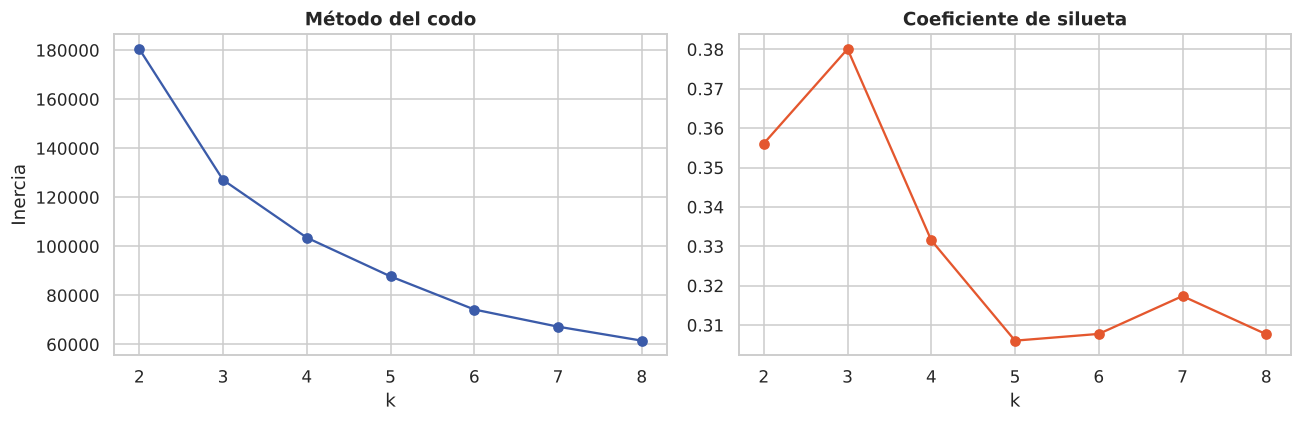

,k,inercia,silueta
0,2,"180,476.56",0.36
1,3,"127,092.30",0.38
2,4,"103,542.73",0.33
3,5,"87,745.88",0.31
4,6,"74,250.98",0.31
5,7,"67,248.50",0.32
6,8,"61,547.22",0.31


In [ ]:
Z = pd.DataFrame({"ln_hog": np.log(d.hog), "ln_val": np.log(d.val), "ln_vh": np.log(d.vh), "anio": d.anio})
Zs = StandardScaler().fit_transform(Z)

ks = range(2, 9)
inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Zs)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(Zs, km.labels_, sample_size=15000, random_state=SEED))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inercia, "o-", color="#3B5BA9"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(list(ks), sil, "o-", color="#E4572E"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inercia": inercia, "silueta": sil}).round(3)

In [ ]:
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Zs)
d["grupo"] = km.labels_

perfil = d.groupby("grupo").agg(
    registros=("val", "size"), hogares_mediana=("hog", "median"), hogares_total=("hog", "sum"),
    valor_total=("val", "sum"), valor_por_hogar_mediana=("vh", "median"),
    anio_mediana=("anio", "median"), anio_min=("anio", "min"), anio_max=("anio", "max"))
perfil["% registros"] = perfil.registros / perfil.registros.sum() * 100
perfil["% hogares"] = perfil.hogares_total / perfil.hogares_total.sum() * 100
perfil["% valor"] = perfil.valor_total / perfil.valor_total.sum() * 100
perfil["valor_total (billones)"] = perfil.valor_total / 1e12
perfil["valor_por_hogar_mediana (millones)"] = perfil.valor_por_hogar_mediana / 1e6
perfil = perfil.drop(columns=["valor_total", "valor_por_hogar_mediana", "hogares_total"])
perfil.round(1)

,registros,hogares_mediana,anio_mediana,anio_min,anio_max,% registros,% hogares,% valor,valor_total (billones),valor_por_hogar_mediana (millones)
grupo,,,,,,,,,,
0,10504,3.00,"2,008.00",2003,2023,15.20,19.30,6.40,1.20,10.20
1,19931,14.00,"2,021.00",2003,2026,28.90,72.30,85.90,16.60,22.70
2,38455,1.00,"2,021.00",2011,2026,55.80,8.30,7.70,1.50,18.40


Composición de cada grupo por programa (%):


prog,Bolsa Desplazados,Casa Digna Vida Digna,MI CASA YA,Otros,Semillero de Propietarios Arriendo,VIPA
grupo,,,,,,
0,51.50,0.00,5.50,43.00,0.00,0.00
1,2.10,10.20,67.80,10.30,4.20,5.40
2,1.40,5.50,74.40,7.10,9.10,2.50


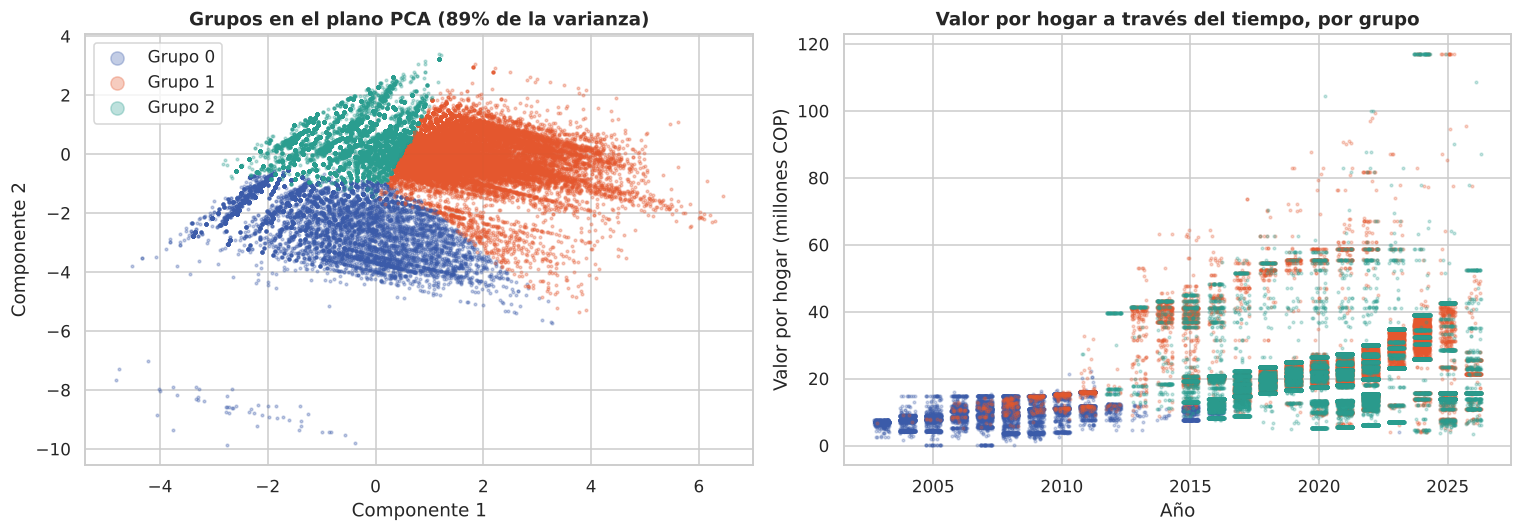

In [ ]:
top5 = d.prog.value_counts().head(5).index
comp = pd.crosstab(d.grupo, d.prog.where(d.prog.isin(top5), "Otros"), normalize="index") * 100
print("Composición de cada grupo por programa (%):")
display(comp.round(1))

pca = PCA(n_components=2, random_state=SEED).fit(Zs)
P = pca.transform(Zs)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
col = ["#3B5BA9", "#E4572E", "#2A9D8F"]
for g in range(K):
    ax[0].scatter(P[d.grupo == g, 0], P[d.grupo == g, 1], s=3, alpha=.3, color=col[g], label=f"Grupo {g}")
ax[0].legend(markerscale=5); ax[0].set_title(f"Grupos en el plano PCA ({pca.explained_variance_ratio_.sum():.0%} de la varianza)")
ax[0].set_xlabel("Componente 1"); ax[0].set_ylabel("Componente 2")
for g in range(K):
    ax[1].scatter(d.anio[d.grupo == g] + np.random.default_rng(1).uniform(-.3, .3, (d.grupo == g).sum()),
                  d.vh[d.grupo == g] / 1e6, s=3, alpha=.25, color=col[g])
ax[1].set_xlabel("Año"); ax[1].set_ylabel("Valor por hogar (millones COP)"); ax[1].set_title("Valor por hogar a través del tiempo, por grupo")
plt.tight_layout(); plt.show()

In [ ]:
# Resumen de cifras clave que se usan en la discusión
print(f"Valor total asignado: {d.val.sum()/1e12:,.2f} billones COP | Hogares: {d.hog.sum():,}")
dep = d.groupby("dep").val.sum().sort_values(ascending=False)
print("Top 3 departamentos por valor (% del total):")
print((dep.head(3) / dep.sum() * 100).round(1).to_string())
pr = d.groupby("prog").val.sum().sort_values(ascending=False)
print("Top 3 programas por valor (% del total):")
print((pr.head(3) / pr.sum() * 100).round(1).to_string())

Valor total asignado: 19.37 billones COP | Hogares: 912,609
Top 3 departamentos por valor (% del total):
dep
VALLE DEL CAUCA   14.60
ATLÁNTICO         12.80
ANTIOQUIA          6.80
Top 3 programas por valor (% del total):
prog
MI CASA YA                           46.00
Programa Vivienda Gratuita Fase I    20.60
Programa Vivienda Gratuita Fase II    7.40


## 7. Discusión de los resultados

### 7.1 Qué muestran los datos

La base final de trabajo tiene 68,890 registros en estado "Asignados", que agrupan 912,609 hogares y 19.37 billones de pesos nominales entre 2003 y 2026. La concentración es fuerte en dos sentidos. Por programa, Mi Casa Ya reúne el 46.0% del valor, Vivienda Gratuita Fase I el 20.6% y Vivienda Gratuita Fase II el 7.4%: tres programas explican cerca de tres cuartas partes de los recursos. Por territorio, Valle del Cauca (14.6%) y Atlántico (12.8%) lideran, por delante de Antioquia (6.8%), un orden que no coincide con el de número de registros, donde Antioquia es el departamento con más filas. La razón es que Atlántico y Valle recibieron proyectos grandes de Vivienda Gratuita y Mi Casa Ya, mientras que en Antioquia abundan las asignaciones pequeñas y dispersas.

La serie anual cuenta una historia de ciclos de política más que de crecimiento continuo. El valor por hogar pasó de unos 7 millones de pesos en 2003 a cerca de 36 y 39 millones en 2013 y 2014, el periodo de Vivienda Gratuita, para bajar a entre 22 y 24 millones entre 2020 y 2022, subir a 30 y 31 millones en 2023 y 2024 y caer a 20 y 19 millones en 2025 y 2026. Los hogares atendidos tuvieron su pico en 2021 (85,693) y 2022 (84,162), y en 2026 la cifra es de apenas 16,266, algo esperable porque el año aún no cierra y porque el flujo de registros cambia con cada gobierno. Hay que tener presente que todo está en pesos corrientes: parte del aumento del valor por hogar es inflación y actualización del monto del subsidio, no necesariamente un subsidio "más generoso" en términos reales.

### 7.2 Modelo de pronóstico: regresión lineal

La primera lección es que la forma funcional importa más que el algoritmo. La correlación entre hogares y valor es 0.755 en la escala original, pero sube a 0.936 en escala logarítmica. La razón es que la relación es esencialmente **proporcional** (más hogares, proporcionalmente más pesos), y las colas largas de ambas variables arruinan un ajuste lineal en pesos: unos pocos registros de más de mil hogares dominan la suma de cuadrados.

Los resultados en el periodo de prueba (2023 a 2026, 13,232 registros que el modelo nunca vio) lo confirman:

- La **regresión lineal en pesos** tiene un MAE de 216.8 millones, un RMSE de 401.4 millones y un R² de 0.73. Es peor que la regla simple de referencia (hogares por el valor medio por hogar), que logra MAE de 130.6 millones y R² de 0.76. Además, su R² en escala log es negativo (-0.92) porque produce pronósticos absurdos (incluso negativos, que tuvimos que recortar en cero) para registros pequeños.
- La **regresión log-log** reduce el MAE a 40.5 millones, la mediana del error absoluto a 10.2 millones, el RMSE a 161.3 millones y eleva el R² a 0.96 (0.97 en escala log). Frente al baseline, el error promedio cae un 69% y el error típico (mediana) un 70%.
- El 88.1% de los registros de prueba se pronostica con un error relativo menor al 25% y el 96.0% con un error menor al 50%.
- Agregado por año, el valor total pronosticado se desvía solo -0.65% en 2023, +2.11% en 2024, +11.46% en 2025 y -0.88% en 2026. El 2025 es el único año con una sobreestimación relevante, coherente con la caída del valor por hogar a 20.2 millones que el modelo, que proyecta una tendencia creciente, no anticipó.

La interpretación de los coeficientes es útil para negocio. La elasticidad de los hogares es de 1.002: cada 1% adicional de hogares en un registro se asocia a un 1.0% adicional de valor, es decir, **el costo marginal por hogar es prácticamente constante** dentro de un programa y no hay economías de escala visibles en el monto del subsidio. El coeficiente del año equivale a un aumento de 11.4% anual en el valor de un registro comparable (el intercepto es muy negativo solo porque el año no está centrado). Las diferencias por programa, medidas contra Bolsa Desplazados, ordenan los programas por intensidad del subsidio: Vivienda Gratuita Fase I es 56.4% mayor, mientras que Mi Casa Ya es 49.2% menor, Casa Digna Vida Digna 78.3% menor y Semillero de Propietarios Ahorro 87.8% menor. Debe leerse con cautela, porque el programa de referencia opera sobre todo en los primeros años de la serie y la comparación "a igual año" implica extrapolar, pero el orden general (vivienda completa gratuita muy por encima de mejoramientos y esquemas de ahorro) es consistente con la naturaleza de cada programa.

### 7.3 Modelo de agrupamiento: K-Means

El coeficiente de silueta fue máximo con k = 3 (0.38), seguido de k = 2 (0.36), y el método del codo no muestra un quiebre tajante. Un valor de 0.38 indica una estructura real pero moderada: los grupos no están perfectamente separados, hay un continuo entre ellos. Elegimos k = 3 por ser el criterio matemático más sólido y, sobre todo, porque produce perfiles interpretables:

1. **Grupo 0, el legado de los primeros años (10,504 registros, 15.2%).** Mediana de 3 hogares, valor por hogar de 10.2 millones y año mediano 2008. Más de la mitad son Bolsa Desplazados y un 43% está en programas poco frecuentes. Concentra el 19.3% de los hogares pero solo el 6.4% del valor (1.2 billones), porque los subsidios eran de montos bajos.
2. **Grupo 1, los grandes proyectos (19,931 registros, 28.9%).** Mediana de 14 hogares y 22.7 millones por hogar. Aunque son menos de un tercio de los registros, acumulan el 72.3% de los hogares y el **85.9% del valor (16.6 billones)**. Predomina Mi Casa Ya (68% de los registros) y aquí está el grueso de Vivienda Gratuita, que por sí sola aporta el 32% del valor del grupo.
3. **Grupo 2, las asignaciones individuales recientes (38,455 registros, 55.8%).** Mediana de 1 hogar, 18.4 millones por hogar, años 2011 a 2026 y 74% de Mi Casa Ya. Son más de la mitad de las filas, pero solo el 8.3% de los hogares y el 7.7% del valor.

El hallazgo de gestión es contundente: la lectura por número de registros engaña. El 55.8% del trabajo administrativo (registros) mueve menos del 8% de los recursos, mientras que el 28.9% de registros decide más del 85% del presupuesto. Cualquier control, auditoría o proyección de recursos tendría más retorno si se concentra en el Grupo 1.

### 7.4 Los dos modelos juntos

Los modelos se complementan. K-Means explica por qué un modelo único es difícil: conviven al menos tres lógicas de asignación con escalas distintas, y por eso la regresión funciona bien solo cuando se expresa en proporciones (log-log). A su vez, la regresión ofrece al agrupamiento una referencia: el valor por hogar esperado para cada programa y año. Un registro con un valor muy distinto al pronosticado es un candidato natural para revisión.

### 7.5 Qué significa para la toma de decisiones

- Para **presupuestar**, el modelo log-log permite estimar con un error típico de 10 millones por registro (y de menos del 3% a nivel agregado en tres de los cuatro años de prueba) cuánto costará una cohorte de hogares de un programa dado.
- Para **priorizar controles**, el Grupo 1 concentra el riesgo fiscal.
- Para **evaluar equidad territorial**, la brecha entre el peso de Valle y Atlántico y el de departamentos con pocos registros (como Vaupés, con 8 registros en toda la base original, o Guainía, con 40) merece contrastarse con indicadores de déficit habitacional que esta base no incluye.

## 8. Posibles limitaciones y retos

- **Datos agregados y sin identificador.** Cada fila resume varios hogares y no hay un ID de registro; por eso no es posible modelar a nivel de hogar ni distinguir duplicados reales de combinaciones idénticas legítimas (30,393 filas son duplicados exactos y se conservaron deliberadamente).
- **Pesos corrientes.** No se deflactó el valor. La tendencia de 11.4% anual mezcla inflación, ajuste del monto del subsidio y cambios de composición entre programas. Un análisis en pesos constantes (por ejemplo, en salarios mínimos) sería el siguiente paso.
- **Pocas variables explicativas.** La base no trae ingreso del hogar, tamaño del municipio, déficit habitacional, tipo de vivienda ni fecha exacta. Es lo que limita la capacidad predictiva más allá de "hogares, programa, lugar y año".
- **El año como variable lineal.** Asume una tendencia constante y, por eso, el 2025 se sobreestimó 11.5%. Los programas cambian por decisión política, algo que ningún modelo estadístico anticipa.
- **Confusión programa y periodo.** Varios programas existieron solo en ciertos años, lo que dificulta separar el "efecto programa" del "efecto año".
- **Estructura moderada de los grupos.** Una silueta de 0.38 indica fronteras difusas. K-Means asume grupos esféricos y es sensible a la escala y a los valores atípicos, aunque se mitigó con logaritmos y estandarización.
- **Año en curso incompleto.** 2026 solo incluye asignaciones hasta la fecha de descarga de la base (14 de noviembre de 2026).
- **Estados excluidos.** Se modelaron solo asignaciones efectivas; los subsidios vencidos, renunciados o revocados (más de 18,000 registros) merecen su propio análisis de clasificación.

## 9. Consideraciones éticas y prácticas

- **Privacidad.** La base no contiene datos personales: son totales por programa, municipio y año. Aun así, en municipios pequeños con 1 o 2 hogares un registro podría permitir inferencias, por lo que cualquier cruce con otras fuentes debe respetar la Ley 1581 de 2012 de protección de datos personales.
- **Uso de los modelos.** Los modelos describen y pronostican montos agregados. **No deben usarse para decidir quién recibe un subsidio**, pues no tienen información de necesidad ni de derechos de los hogares, y automatizar esa decisión con datos históricos podría perpetuar sesgos territoriales.
- **Equidad.** Que un departamento reciba más o menos recursos refleja decisiones de política, tamaño de proyectos y capacidad de gestión de los entes territoriales, no necesariamente necesidad. Las conclusiones territoriales deben acompañarse de datos de déficit habitacional y población.
- **Transparencia y reproducibilidad.** El código, la semilla aleatoria y las decisiones de limpieza están documentados en este notebook y en GitHub para que cualquiera pueda auditarlos.
- **Prácticas.** Se recomienda reentrenar los modelos cada año, monitorear el error por programa y no extrapolar a programas nuevos sin datos. Las cifras deben comunicarse con su incertidumbre (por ejemplo, el rango de error), no como valores exactos.
- **Uso de la fuente.** Los datos son abiertos del Gobierno de Colombia; se cita la fuente y no se alteran los valores originales.

## 10. Conclusiones

1. La base de subsidios de vivienda está muy concentrada: tres programas (Mi Casa Ya, Vivienda Gratuita Fase I y Fase II) suman cerca del 74% del valor asignado, y Valle del Cauca y Atlántico, el 27.4%.
2. El valor asignado es **proporcional al número de hogares** (elasticidad 1.002). No hay economías de escala visibles en el monto del subsidio por hogar.
3. La regresión lineal en pesos **no supera** una regla simple de referencia; la regresión **log-log** sí lo hace con claridad: R² de 0.96, MAE de 40.5 millones frente a 130.6 millones del baseline y 88.1% de los registros de prueba con error menor al 25%.
4. A nivel agregado, el pronóstico anual de valor se desvía entre -0.9% y +2.1% en tres de los cuatro años de prueba; el cuarto, 2025, se sobreestima 11.5% por un cambio de política que el modelo no puede ver.
5. K-Means identifica tres perfiles: legado de los primeros años (6.4% del valor), grandes proyectos (85.9% del valor con 28.9% de los registros) y asignaciones individuales recientes (55.8% de los registros, 7.7% del valor).
6. La estructura de grupos es real pero moderada (silueta 0.38), por lo que los perfiles sirven como guía de gestión y no como fronteras rígidas.

## 11. Recomendaciones

**Para la entidad que asigna y presupuesta**
1. Presupuestar con el modelo log-log por programa, no con un valor promedio global, y publicar el rango de error junto a cada pronóstico.
2. Concentrar auditoría, seguimiento de ejecución y gestión de riesgo en los grandes proyectos (Grupo 1), que mueven más del 85% de los recursos.
3. Simplificar la gestión de las asignaciones individuales (Grupo 2) con procesos estandarizados, porque son más de la mitad de los registros con menos del 8% del valor.
4. Contrastar la distribución territorial con indicadores de déficit habitacional antes de afirmar que existen brechas de equidad.
5. Incorporar un identificador de registro, el ingreso del hogar y el tamaño de la vivienda a la base abierta, para habilitar análisis más finos.

**Para continuar el trabajo analítico**
1. Repetir el análisis en pesos constantes (o en salarios mínimos).
2. Entrenar un modelo de **clasificación** del estado de la postulación (asignado, vencido, renunciado) para anticipar subsidios que no se ejecutan.
3. Probar modelos no lineales (árboles, bosques aleatorios) y un pronóstico de series de tiempo por programa.
4. Reentrenar anualmente y monitorear el error por programa.

## 12. Bibliografía

- Congreso de la República de Colombia. (1991). *Ley 3 de 1991, por la cual se crea el Sistema Nacional de Vivienda de Interés Social y se establece el subsidio familiar de vivienda.*
- Congreso de la República de Colombia. (2012). *Ley 1581 de 2012, por la cual se dictan disposiciones generales para la protección de datos personales.*
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association, 78*(383), 605-610.
- Gobierno de Colombia. (2026). *Subsidios de Vivienda Asignados* [Conjunto de datos abiertos]. Portal de datos abiertos (datos.gov.co). Archivo descargado el 14 de noviembre de 2026.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.). Springer.
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability, 1*, 281-297.
- Pedregosa, F., et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65.
- Material y clases del curso de Analítica de Negocios, Universidad EAFIT (2026).